In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

log_returns = pd.read_csv("../data/processed/log_returns.csv", parse_dates=True, index_col=0)
log_returns.head()

,HDFCBANK.NS,ITC.NS,RELIANCE.NS,SUNPHARMA.NS,TCS.NS,^NSEI
Date,,,,,,
2020-01-02,0.006354,0.007323,0.016881,0.001496,-0.004601,0.008151
2020-01-03,-0.014363,-0.005645,0.001204,0.021944,0.019733,-0.004533
2020-01-06,-0.021879,-0.014358,-0.023465,-0.010514,-0.000091,-0.019291
2020-01-07,0.015711,0.001063,0.015267,0.014554,0.002451,0.004982
2020-01-08,-0.002621,-0.004898,-0.007538,-0.014213,0.022148,-0.002293


In [2]:
annual_return = log_returns.mean() * 252
annual_vol = log_returns.std() * np.sqrt(252)
sharpe = annual_return / annual_vol

summary = pd.DataFrame({
    "Annual return": annual_return,
    "Annual volatility": annual_vol,
    "Sharpe ratio": sharpe
})
print(summary.round(4))

              Annual return  Annual volatility  Sharpe ratio
HDFCBANK.NS          0.0749             0.2734        0.2739
ITC.NS               0.1901             0.2599        0.7316
RELIANCE.NS          0.1189             0.2968        0.4007
SUNPHARMA.NS         0.3097             0.2547        1.2159
TCS.NS               0.1495             0.2447        0.6109
^NSEI                0.1351             0.1928        0.7005


In [3]:
summary.to_csv("../data/processed/risk_summary.csv")

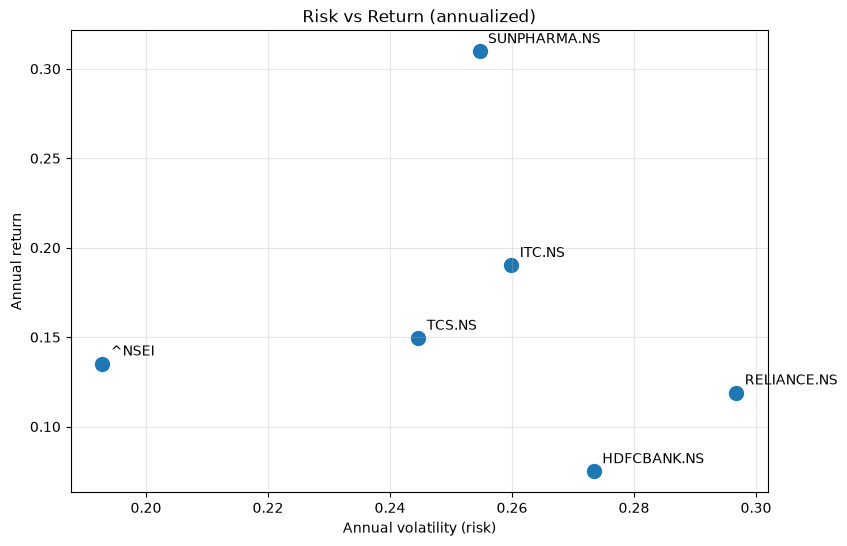

In [4]:
plt.figure(figsize=(9, 6))
plt.scatter(summary["Annual volatility"], summary["Annual return"], s=100)

for name in summary.index:
    plt.annotate(name, (summary.loc[name, "Annual volatility"], summary.loc[name, "Annual return"]),
                 textcoords="offset points", xytext=(6, 6))

plt.title("Risk vs Return (annualized)")
plt.xlabel("Annual volatility (risk)")
plt.ylabel("Annual return")
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/risk_vs_return.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

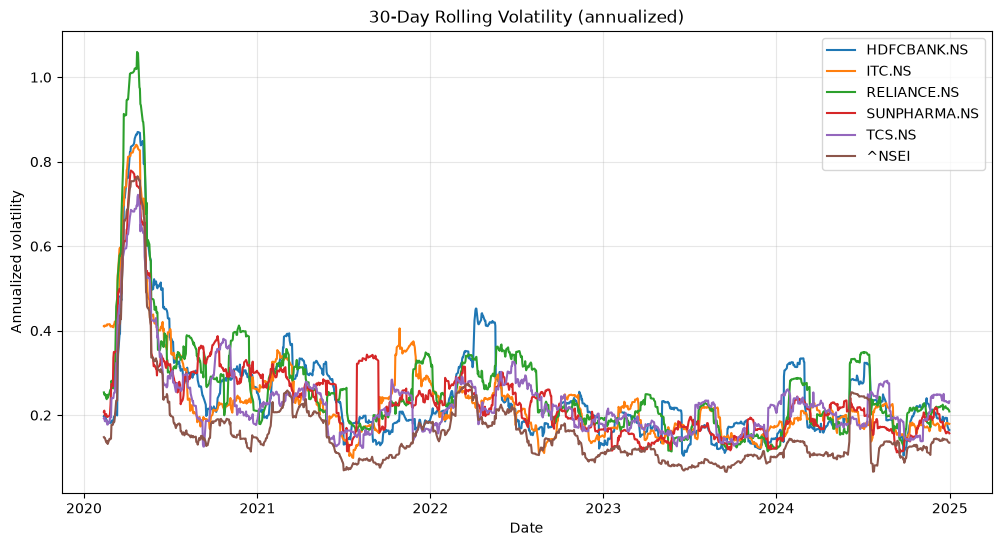

In [5]:
rolling_vol = log_returns.rolling(30).std() * np.sqrt(252)

plt.figure(figsize=(12, 6))
for col in rolling_vol.columns:
    plt.plot(rolling_vol.index, rolling_vol[col], label=col)

plt.title("30-Day Rolling Volatility (annualized)")
plt.xlabel("Date")
plt.ylabel("Annualized volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/rolling_volatility.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [6]:
prices = pd.read_csv("../data/processed/prices_clean.csv", parse_dates=True, index_col=0)

cum_value = prices / prices.iloc[0]
running_max = cum_value.cummax()
drawdown = cum_value / running_max - 1

max_drawdown = drawdown.min()
print(max_drawdown.round(4))

HDFCBANK.NS    -0.4047
ITC.NS         -0.3947
RELIANCE.NS    -0.4408
SUNPHARMA.NS   -0.2810
TCS.NS         -0.2675
^NSEI          -0.3844
dtype: float64


In [7]:
var_95 = log_returns.apply(lambda r: np.percentile(r, 5))
print(var_95.round(4))

HDFCBANK.NS    -0.0247
ITC.NS         -0.0208
RELIANCE.NS    -0.0244
SUNPHARMA.NS   -0.0223
TCS.NS         -0.0218
^NSEI          -0.0164
dtype: float64


In [8]:
summary["Max drawdown"] = max_drawdown
summary["VaR 95% (daily)"] = var_95
print(summary.round(4))
summary.to_csv("../data/processed/risk_summary.csv")

              Annual return  Annual volatility  Sharpe ratio  Max drawdown  \
HDFCBANK.NS          0.0749             0.2734        0.2739       -0.4047   
ITC.NS               0.1901             0.2599        0.7316       -0.3947   
RELIANCE.NS          0.1189             0.2968        0.4007       -0.4408   
SUNPHARMA.NS         0.3097             0.2547        1.2159       -0.2810   
TCS.NS               0.1495             0.2447        0.6109       -0.2675   
^NSEI                0.1351             0.1928        0.7005       -0.3844   

              VaR 95% (daily)  
HDFCBANK.NS           -0.0247  
ITC.NS                -0.0208  
RELIANCE.NS           -0.0244  
SUNPHARMA.NS          -0.0223  
TCS.NS                -0.0218  
^NSEI                 -0.0164  


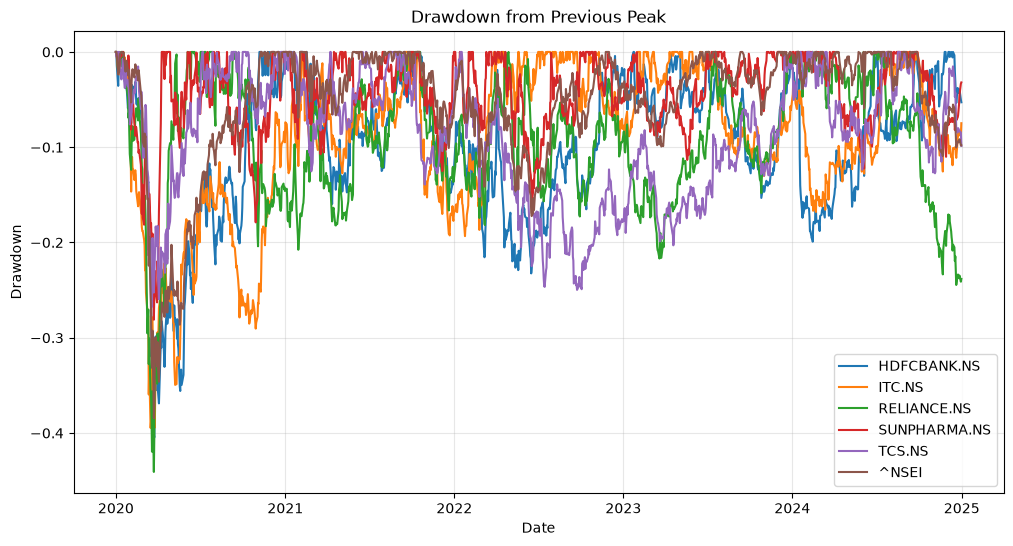

In [9]:
plt.figure(figsize=(12, 6))
for col in drawdown.columns:
    plt.plot(drawdown.index, drawdown[col], label=col)

plt.title("Drawdown from Previous Peak")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/drawdown.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [10]:
corr = log_returns.corr()
print(corr.round(2))

              HDFCBANK.NS  ITC.NS  RELIANCE.NS  SUNPHARMA.NS  TCS.NS  ^NSEI
HDFCBANK.NS          1.00    0.30         0.44          0.27    0.32   0.76
ITC.NS               0.30    1.00         0.31          0.30    0.25   0.51
RELIANCE.NS          0.44    0.31         1.00          0.32    0.39   0.72
SUNPHARMA.NS         0.27    0.30         0.32          1.00    0.28   0.47
TCS.NS               0.32    0.25         0.39          0.28    1.00   0.59
^NSEI                0.76    0.51         0.72          0.47    0.59   1.00


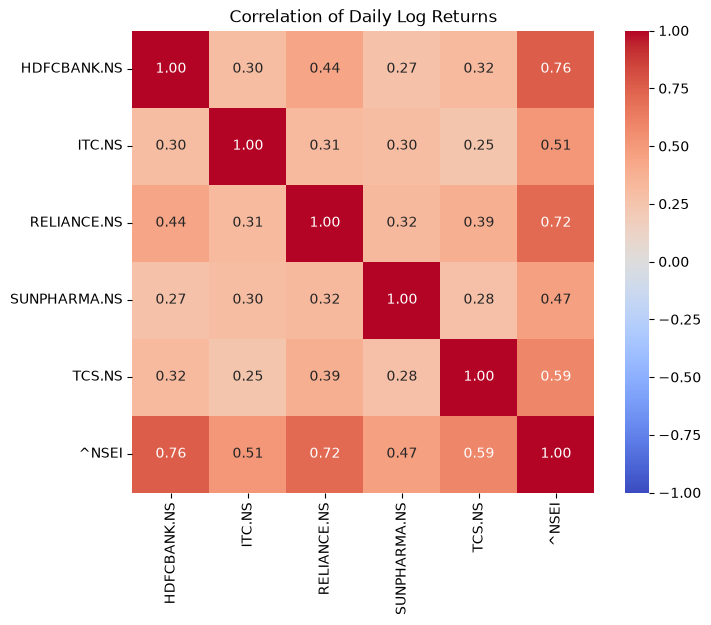

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation of Daily Log Returns")
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [12]:
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs = pairs.sort_values(ascending=False)
print("Highest correlations:")
print(pairs.head(3).round(2))
print("\nLowest correlations:")
print(pairs.tail(3).round(2))

Highest correlations:
HDFCBANK.NS  ^NSEI    0.76
RELIANCE.NS  ^NSEI    0.72
TCS.NS       ^NSEI    0.59
dtype: float64

Lowest correlations:
^NSEI  SUNPHARMA.NS   NaN
       TCS.NS         NaN
       ^NSEI          NaN
dtype: float64
